# 川口市の地区での実験：地区ごとの巡回路長の推定

## 環境構築

In [22]:
!uv pip install elkai numpy pandas matplotlib geopandas tqdm contextily

Checked 7 packages in 51ms


In [2]:
!uv pip show matplotlib

Name: matplotlib
Version: 3.9.4
Location: /Users/hasega60/.cache/uv/builds-v0/.tmpFQK232/lib/python3.9/site-packages
Requires: contourpy, cycler, fonttools, importlib-resources, kiwisolver, numpy, packaging, pillow, pyparsing, python-dateutil
Required-by: contextily


In [3]:
import json
import re
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import shapely
from shapely.geometry import Polygon, MultiPolygon

from tqdm.auto import tqdm
import os
from elkai import _elkai

/Users/hasega60/Dropbox/work/research/00_paper/202610_COR/.venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 設定

In [4]:
N_TOTAL = 2000   # 市全体の点数（世帯数に比例して地区に配分）
REPS = 500
MAX_TRIALS = 100
SCALE = 1e5
rng = np.random.default_rng(0)
TOL = 0.25   # 許容誤差torelance = TOL × a

b_CALC_TOUR = False   # 再度LKHで巡回距離を求めるか

# notebook 1 で推定した値
prm = pd.read_csv("../output/table_parameters.csv").set_index(["model", "parameter"])["estimate"]   # キャリブレーション結果を読み込む
beta, gamma = prm["PC-Const", "beta"], prm["PC-Const", "gamma"]
gamma_inf, c = prm["PC-FN", "gamma_inf"], prm["PC-FN", "c"]
beta_cal = prm["BHH-R", "beta"]
kw = prm["KWON-R"][["k0", "k1 (N)", "k2 (S/N)"]].values
hs = prm["HS-R"][["h1 (sqrt N)", "h2 (S/sqrt N)", "h3 (const.)"]].values



## 川口市のデータ読み込み

2020年国勢調査 小地域（町丁・字）境界データ（e-Stat）。地区は川口市「地区分類一覧」による。

In [5]:
gdf_city = gpd.read_file("../data/r2ka11203.gml")   # EPSG:2451（平面直角座標系第IX系，メートル座標系）


gdf_city["JINKO"] = gdf_city.JINKO.astype(int)
gdf_city["SETAI"] = gdf_city.SETAI.astype(int)

df_district = pd.read_csv(f"../data/district.csv", encoding="cp932")
DISTRICTS = df_district["district"].unique()
DISTRICTS.sort()

gdf_city = gdf_city.merge(df_district[["KEY_CODE","district"]], how="left", on="KEY_CODE")

def drop_slivers(gm, min_hole=1000):   # 町丁境界のすき間による面積ほぼ0の穴を除去
    ps = [Polygon(p.exterior, [h for h in p.interiors if Polygon(h).area > min_hole]) for p in getattr(gm, "geoms", [gm])]
    return ps[0] if len(ps) == 1 else MultiPolygon(ps)

dist = gdf_city.dissolve(by="district", aggfunc={"JINKO": "sum", "SETAI": "sum"})
dist["geometry"] = dist.geometry.buffer(0).apply(drop_slivers)
dist = dist.loc[list(DISTRICTS)]

/Users/hasega60/Dropbox/work/research/00_paper/202610_COR/.venv/lib/python3.9/site-packages/pyogrio/raw.py:198: RuntimeWarning: Value '-' of field r2ka11203.DUMMY1 parsed incompletely to integer 0.
  return ogr_read(


In [6]:
df_district

,KEY_CODE,PREF,CITY,S_AREA,PREF_NAME,CITY_NAME,S_NAME,district
0,11203001001,11,203,1001,埼玉県,川口市,本町一丁目,8.Chuo
1,11203001002,11,203,1002,埼玉県,川口市,本町二丁目,8.Chuo
2,11203001003,11,203,1003,埼玉県,川口市,本町三丁目,8.Chuo
3,11203001004,11,203,1004,埼玉県,川口市,本町四丁目,8.Chuo
4,11203002001,11,203,2001,埼玉県,川口市,栄町一丁目,8.Chuo
...,...,...,...,...,...,...,...,...
279,11203118004,11,203,118004,埼玉県,川口市,戸塚南四丁目,0.Totsuka
280,11203118005,11,203,118005,埼玉県,川口市,戸塚南五丁目,0.Totsuka
281,11203119001,11,203,119001,埼玉県,川口市,本前川一丁目,4.Aoki
282,11203119002,11,203,119002,埼玉県,川口市,本前川二丁目,4.Aoki


In [7]:
DISTRICTS

array(['0.Totsuka', '1.Kamine', '2.Angyo', '3.Shiba', '4.Aoki',
       '5.Hatogaya', '6.Shingo', '7.Yokozone', '8.Chuo', '9.Nanpei'],
      dtype=object)

## 世帯のコロプレスマップと各地区の n

In [8]:
dist["n"] = (N_TOTAL * dist.SETAI/dist.SETAI.sum()).round().astype(int)
dist["A_km2"] = dist.area/1e6
dist["a_m"] = np.sqrt(dist.area/dist.n)
dist["P_km_org"] = dist.length / 1e3   # 元の境界の長さ（簡略化なし）
dist["P_km"] = [p.boundary.simplify(a*TOL).length/1e3 for p, a in zip(dist.geometry, dist.a_m)]   # simplifyした後の周長
dist["S"] = dist.P_km / np.sqrt(dist.A_km2)


dist.round(2)

,geometry,JINKO,SETAI,n,A_km2,a_m,P_km_org,P_km,S
district,,,,,,,,,
0.Totsuka,"POLYGON ((-8346.385 -15142.3, -8346.735 -15142...",69563,29084,207,7.46,189.88,22.14,20.45,7.49
1.Kamine,"POLYGON ((-9674.786 -17410.079, -9707.355 -174...",68447,25875,184,9.82,231.02,20.39,18.59,5.93
2.Angyo,"POLYGON ((-6818.759 -18212.154, -6799.44 -1823...",43622,16460,117,5.63,219.27,14.22,13.10,5.52
3.Shiba,"POLYGON ((-13047.432 -18949.648, -13052.185 -1...",91338,44077,314,6.54,144.37,16.38,15.52,6.06
4.Aoki,"POLYGON ((-10762.399 -20727.207, -10764.252 -2...",76674,35066,250,6.21,157.57,13.23,13.01,5.22
5.Hatogaya,"POLYGON ((-8389.829 -20798.318, -8397.502 -208...",64011,28355,202,6.20,175.14,16.87,15.23,6.12
6.Shingo,"POLYGON ((-7720.137 -18753.16, -7719.619 -1869...",38675,15356,109,6.57,245.50,13.49,12.27,4.79
7.Yokozone,"POLYGON ((-12281.526 -22078.904, -12412.065 -2...",70307,36770,262,4.18,126.38,11.71,11.50,5.62
8.Chuo,"POLYGON ((-10466.097 -22756.562, -10548.527 -2...",42723,21201,151,2.24,121.83,8.10,8.01,5.35


In [9]:
TOLS = {"a": 1, "a/2": 1 / 2, "a/4": 1 / 4, "a/8": 1 / 8}   # 許容誤差（a の倍数）
p_tol = pd.DataFrame({lab: [p.simplify(k * a).length / p.length for p, a in zip(dist.geometry, dist.a_m)] for lab, k in TOLS.items()},
                     index=dist.index)   # P/P0
display(p_tol.round(3))
p_tol.round(3).to_csv(f"../output/table_districts_simplify_tolerance_N{N_TOTAL}.csv")

ZOOM = p_tol["a/2"].nsmallest(3).index   # 周長の差が大きい 3 地区
W = 750   # 拡大範囲の半幅（m）

,a,a/2,a/4,a/8
district,,,,
0.Totsuka,0.823,0.877,0.924,0.957
1.Kamine,0.789,0.863,0.912,0.946
2.Angyo,0.833,0.866,0.922,0.952
3.Shiba,0.867,0.911,0.947,0.979
4.Aoki,0.954,0.973,0.984,0.994
5.Hatogaya,0.756,0.837,0.903,0.948
6.Shingo,0.789,0.867,0.910,0.945
7.Yokozone,0.924,0.962,0.982,0.990
8.Chuo,0.914,0.985,0.989,0.995


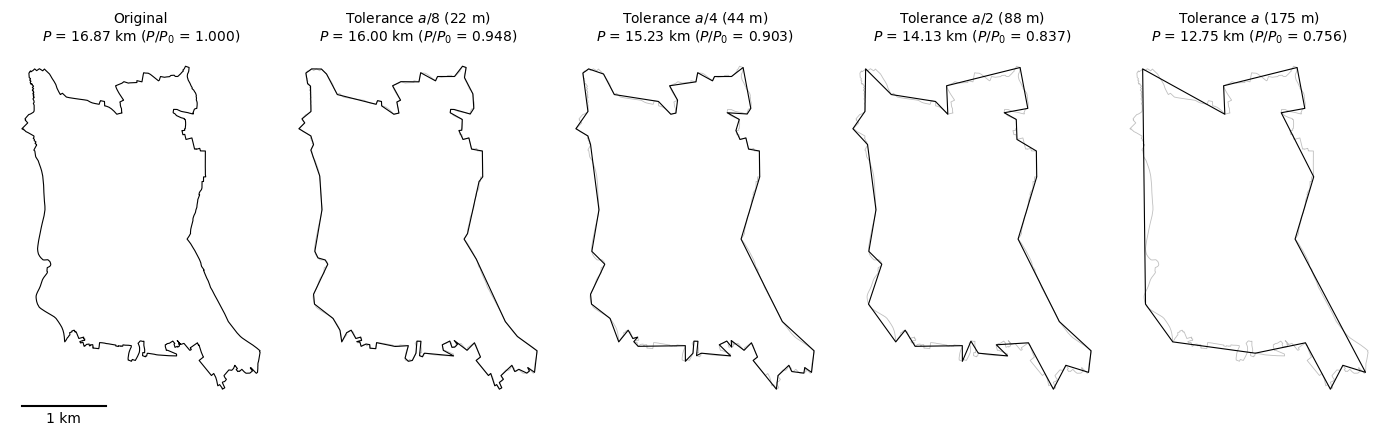

In [10]:
D = "5.Hatogaya"
PANELS = {"Original": 0, "a/8": 1/8, "a/4": 1/4, "a/2": 1/2, "a": 1}   # 左から右へ簡略化が強くなる順（0 は元の境界）
p, a = dist.geometry[D], dist.a_m[D]
fig, axes = plt.subplots(1, len(PANELS), figsize=(14, 4.6), sharex=True, sharey=True)
for ax, (lab, k) in zip(axes, PANELS.items()):
    q = p.simplify(k * a) if k else p
    if k:
        gpd.GeoSeries([p.boundary]).plot(ax=ax, color="0.75", lw=0.6)   # 元の境界（薄く）
    gpd.GeoSeries([q.boundary]).plot(ax=ax, color="k", lw=0.8)
    head = "Original" if not k else f"Tolerance ${lab}$ ({k * a:.0f} m)"
    ax.set_title(f"{head}\n$P$ = {q.length / 1e3:.2f} km ($P/P_0$ = {q.length / p.length:.3f})", fontsize=10)
    ax.set_aspect("equal")
    ax.set_axis_off()
x0, y0, _, _ = p.bounds
axes[0].plot([x0, x0 + 1000], [y0 - 200, y0 - 200], color="k", lw=1.5)   # 1 km
axes[0].text(x0 + 500, y0 - 260, "1 km", ha="center", va="top", fontsize=10)
#fig.text(0.5, 0.1, f"{D} (N = {dist.n[D]}, $a$ = {a:.0f} m)", ha="center", va="bottom", fontsize=10)   
plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.savefig(f"../output/fig5_{D}_simplify_tolerance.pdf", dpi=300, bbox_inches="tight")
plt.show()

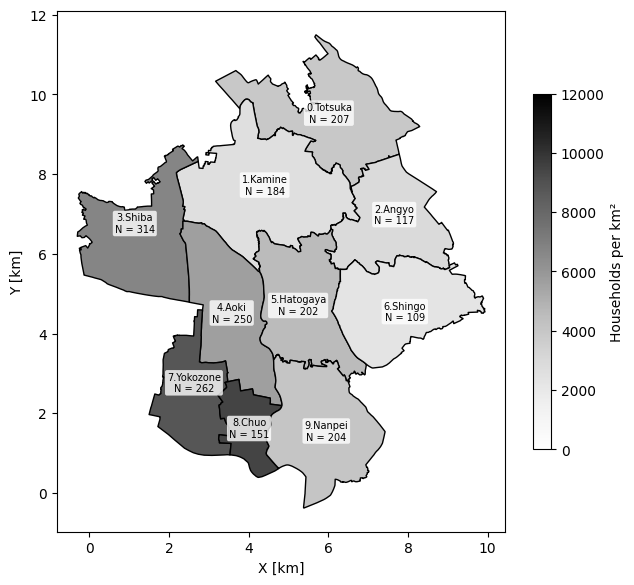

In [11]:
dist["hh_density"] = dist.SETAI / dist.A_km2   # 地区ごとの世帯密度
fig, ax = plt.subplots(figsize=(6.5, 6.5))
dist.plot(ax=ax, column="hh_density", cmap="Greys", vmin=0, vmax=12000, edgecolor="k", linewidth=1.0, legend=True,
          legend_kwds={"label": "Households per km²", "shrink": 0.6})
for d, r in dist.iterrows():
    q = r.geometry.representative_point()
    ax.annotate(f"{d}\nN = {r.n}", (q.x, q.y), ha="center", va="center", fontsize=7,
                bbox=dict(boxstyle="round,pad=0.2", fc="w", ec="none", alpha=0.8))
    
#ax.set_axis_off()
ax.set_xlabel("X [km]")
ax.set_ylabel("Y [km]")
ax.xaxis.set_major_formatter(lambda v, p: f"{(v+14000) / 1000:.0f}")
ax.yaxis.set_major_formatter(lambda v, p: f"{(v+24000) / 1000:.0f}")

plt.tight_layout()
plt.savefig("../output/fig4_kawaguchi_districts.pdf", dpi=300)
plt.show()

## LKH による巡回路計算（各地区を1台で巡回、地区内で一様）

In [12]:
def sample(p, n):
    x0, y0, x1, y1 = p.bounds
    pts = np.empty((0, 2))
    while len(pts) < n:
        c_ = rng.uniform([x0, y0], [x1, y1], size=(4 * n, 2))
        pts = np.vstack([pts, c_[shapely.contains_xy(p, c_[:, 0], c_[:, 1])]])
    return pts[:n]

def dist_euclid(P):
    return np.sqrt(((P[:, None] - P[None]) ** 2).sum(-1))

def tour_length(D):
    M = np.rint(D * SCALE).astype(int)
    problem = ("TYPE : TSP\n"
               f"DIMENSION : {len(D)}\n"
               "EDGE_WEIGHT_TYPE : EXPLICIT\n"
               "EDGE_WEIGHT_FORMAT : FULL_MATRIX\n"
               "EDGE_WEIGHT_SECTION\n"
               + "\n".join(" ".join(map(str, row)) for row in M) + "\n")
    params = f"RUNS = 1\nMAX_TRIALS = {MAX_TRIALS}\nPROBLEM_FILE = :stdin:\n"
    t = np.array(_elkai.solve_problem(params, problem)) - 1
    t = np.append(t, t[0])
    return D[t[:-1], t[1:]].sum()



## simplifyのパラメータ決定

固定値にするべきか，N依存で変化させるべきかを検討

In [13]:
N_CHECK = [50, 75, 100, 200, 300, 400, 500]
REPS_CHECK = 200


In [14]:
poly = dist.geometry[D]

for D in tqdm(dist.index):
    f = f"../output/results_{D}_byN.json"
    if os.path.exists(f) and b_CALC_TOUR is False:   # 計算済みの地区は飛ばす
        print(f"{f} exists")
        continue
    poly = dist.geometry[D]
    L_chk = {}
    for N in N_CHECK:
        L_chk[N] = [tour_length(dist_euclid(sample(poly, N) / 1000)) for _ in range(REPS_CHECK)]   # 巡回路長（km）
    
    json.dump(L_chk, open(f, "w"))

100%|███████████████████████████████████████| 10/10 [00:00<00:00, 12035.31it/s]

../output/results_0.Totsuka_byN.json exists
../output/results_1.Kamine_byN.json exists
../output/results_2.Angyo_byN.json exists
../output/results_3.Shiba_byN.json exists
../output/results_4.Aoki_byN.json exists
../output/results_5.Hatogaya_byN.json exists
../output/results_6.Shingo_byN.json exists
../output/results_7.Yokozone_byN.json exists
../output/results_8.Chuo_byN.json exists
../output/results_9.Nanpei_byN.json exists


In [15]:
# 必要な周長と許容誤差の逆算、ルール別の PE

# a 依存と固定値
RULES = {"none": lambda a: 0,
         "a/8": lambda a: a/8, 
         "a/4": lambda a: a/4, 
         "a/2": lambda a: a/2, 
         "a": lambda a: a,
         "10 m": lambda a: 10, 
         "25 m": lambda a: 25, 
         "50 m": lambda a: 50, 
         "100 m": lambda a: 100, 
         "200 m": lambda a: 200}   
GAMMA = {"PC-Const": lambda N: gamma, "PC-FN": lambda N: gamma_inf + c / np.sqrt(N)}

rows = []
for D in dist.index:
    poly = dist.geometry[D]
    A = poly.area / 1e6
    f = f"../output/results_{D}_byN.json"
    L_chk = {int(k): np.array(v) for k, v in json.load(open(f)).items()}
    for r, f in RULES.items():
        for N in N_CHECK:
            a = np.sqrt(poly.area / N)          # 点の間隔（m）
            t = f(a)                            # ルールの許容誤差（m）：a 依存なら a/8 など、固定値なら a によらず一定
            P = poly.simplify(t).length / 1e3   # 簡略化後の周長
            for m, g in GAMMA.items():
                rows.append({"district": D, "rule": r, "N": N, "model": m, "tolerance (m)": t,
                             "PE": ((beta * np.sqrt(N * A) + g(N) * P) / L_chk[N].mean() - 1) * 100})
                
pe_all = pd.DataFrame(rows)
pe_all.to_csv("../output/table_districts_tolerance_PE_all.csv", index=False)

def summarize(model, Ns):   # 行：ルール、列：地区ごとの平均 |PE|（N について）と全地区の要約
    x = pe_all[(pe_all["model"] == model) & pe_all["N"].isin(Ns)]
    s = x.groupby(["rule", "district"])["PE"].apply(lambda v: v.abs().mean()).unstack().loc[list(RULES), list(dist.index)]
    out = s.copy()
    out["mean"] = s.mean(axis=1)
    out["mean PE"] = x.groupby("rule")["PE"].mean().loc[list(RULES)]                          # 符号付きの平均（過大・過小の偏り）
    out["max |PE|"] = x.groupby("rule")["PE"].apply(lambda v: v.abs().max()).loc[list(RULES)]
    out["best (districts)"] = s.idxmin().value_counts().reindex(list(RULES), fill_value=0)   # 平均 |PE| が最小になった地区数
    d = x.pivot_table(index=["rule", "district"], columns="N", values="PE")
    out["drift"] = (d[max(Ns)] - d[min(Ns)]).groupby("rule").mean().loc[list(RULES)]          # PE(N 最大) − PE(N 最小) の地区平均
    return out

summ_fn = summarize("PC-FN", N_CHECK)
summ_const = summarize("PC-Const", N_CHECK)

N_EVAL = {
    "PC-Const": N_CHECK,
    "PC-FN": N_CHECK,
}

display(summ_fn.round(2)); display(summ_const.round(2))
summ_fn.round(3).to_csv("../output/table_districts_tolerance_summary_PC-FN.csv")
summ_const.round(3).to_csv("../output/table_districts_tolerance_summary_PC-Const.csv")

district,0.Totsuka,1.Kamine,2.Angyo,3.Shiba,4.Aoki,5.Hatogaya,6.Shingo,7.Yokozone,8.Chuo,9.Nanpei,mean,mean PE,max |PE|,best (districts),drift
rule,,,,,,,,,,,,,,,
none,0.89,1.29,1.33,0.20,0.18,1.56,1.37,0.75,0.47,1.18,0.92,0.68,4.69,2,-2.24
a/8,0.41,0.84,0.85,0.29,0.27,0.81,0.88,0.89,0.46,0.74,0.64,0.24,3.05,0,-1.29
a/4,0.40,0.74,0.56,0.62,0.32,0.22,0.68,1.00,0.46,0.43,0.54,-0.07,2.13,2,-0.74
a/2,1.08,0.72,0.43,1.04,0.52,0.58,0.46,1.33,0.37,0.17,0.67,-0.52,2.05,4,0.04
a,2.19,1.27,0.63,1.52,0.92,1.46,0.42,1.98,0.86,0.51,1.18,-1.17,3.92,1,1.14
10 m,0.76,1.15,1.13,0.08,0.20,1.30,1.21,0.81,0.47,1.07,0.82,0.53,4.30,1,-2.07
25 m,0.66,1.05,0.92,0.09,0.26,0.91,1.00,0.89,0.47,0.80,0.71,0.31,3.72,0,-1.80
50 m,0.59,0.97,0.79,0.55,0.30,0.45,0.88,0.98,0.48,0.48,0.65,0.02,3.10,0,-1.46
100 m,0.89,1.00,0.62,1.06,0.41,0.45,0.71,1.37,0.56,0.36,0.74,-0.45,2.19,0,-0.90


district,0.Totsuka,1.Kamine,2.Angyo,3.Shiba,4.Aoki,5.Hatogaya,6.Shingo,7.Yokozone,8.Chuo,9.Nanpei,mean,mean PE,max |PE|,best (districts),drift
rule,,,,,,,,,,,,,,,
none,1.03,1.39,1.49,0.50,0.40,1.74,1.50,0.60,0.16,1.32,1.01,0.84,3.85,2,-0.96
a/8,0.30,0.66,1.00,0.66,0.46,0.99,1.02,0.74,0.13,0.88,0.68,0.40,2.27,0,-0.07
a/4,0.27,0.33,0.63,0.77,0.46,0.54,0.70,0.85,0.11,0.57,0.52,0.08,2.27,2,0.44
a/2,0.88,0.36,0.27,0.96,0.62,0.55,0.31,1.18,0.20,0.34,0.57,-0.37,2.75,1,1.16
a,1.99,1.12,0.49,1.37,0.85,1.31,0.27,1.83,0.73,0.45,1.04,-1.02,4.61,1,2.18
10 m,0.81,1.16,1.29,0.45,0.40,1.47,1.34,0.67,0.14,1.21,0.89,0.69,3.47,0,-0.81
25 m,0.45,0.82,1.01,0.45,0.41,1.08,1.08,0.75,0.13,0.93,0.71,0.47,2.92,1,-0.57
50 m,0.09,0.58,0.74,0.55,0.43,0.45,0.83,0.84,0.12,0.60,0.52,0.17,2.33,1,-0.26
100 m,0.71,0.60,0.33,0.91,0.45,0.25,0.50,1.23,0.35,0.16,0.55,-0.31,2.50,2,0.24


In [16]:

def rule_stats(x):   # ルールごとの平均 PE（符号付き）と最大 |PE|（全地区・全 N）
    g = x.groupby("rule")["PE"]
    return pd.DataFrame({"mean PE": g.mean(), "max |PE|": g.apply(lambda v: v.abs().max())}).loc[list(RULES)]

tab_rule = pd.concat({m: rule_stats(pe_all[(pe_all["model"] == m) & pe_all["N"].isin(Ns)]) for m, Ns in N_EVAL.items()}, axis=1)
display(tab_rule.round(2))
tab_rule.round(3).to_csv("../output/table_districts_tolerance_rule_summary.csv")

PC-Const            PC-FN         
       mean PE max |PE| mean PE max |PE|
rule                                    
none      0.84     3.85    0.68     4.69
a/8       0.40     2.27    0.24     3.05
a/4       0.08     2.27   -0.07     2.13
a/2      -0.37     2.75   -0.52     2.05
a        -1.02     4.61   -1.17     3.92
10 m      0.69     3.47    0.53     4.30
25 m      0.47     2.92    0.31     3.72
50 m      0.17     2.33    0.02     3.10
100 m    -0.31     2.50   -0.45     2.19
200 m    -0.87     2.90   -1.00     2.22

In [17]:
res = {d: [] for d in dist.index}
file = "../output/results_districts.json"

if os.path.exists(file) and b_CALC_TOUR is False:
    print(f"{file} exists")
else:
    for _ in tqdm(range(REPS)):
        for d, r in dist.iterrows():
            P = sample(r.geometry, r.n) / 1000   # km
            res[d].append(tour_length(dist_euclid(P)))
    json.dump(res, open(file, "w"))

../output/results_districts.json exists


## 各モデルによる結果の比較

In [18]:
res = json.load(open("../output/results_districts.json"))

prm = pd.read_csv("../output/table_parameters.csv").set_index(["model", "parameter"])["estimate"]   # キャリブレーション結果を読み込む
beta, gamma = prm["PC-Const", "beta"], prm["PC-Const", "gamma"]
gamma_inf, c = prm["PC-FN", "gamma_inf"], prm["PC-FN", "c"]
beta_cal = prm["BHH-R", "beta"]
kw = prm["KWON-R"][["k0", "k1 (N)", "k2 (S/N)"]].values
hs = prm["HS-R"][["h1 (sqrt N)", "h2 (S/sqrt N)", "h3 (const.)"]].values
ch = prm["CHOI-R"][["c0", "c1 (N exponent)", "c2 (S exponent)"]].values

def envelope(p):   # 座標軸に平行な外接長方形（km）：縦横比（長辺/短辺），短辺
    x0, y0, x1, y1 = np.array(p.bounds) / 1000
    W, H = x1 - x0, y1 - y0
    return max(W, H) / min(W, H), min(W, H)


# Cavdar and Sokol
def cavdar_sokol(p, N):
    X = sample(p, 20000) / 1000
    x0, y0, x1, y1 = np.array(p.bounds) / 1000
    cx, cy = np.abs(X[:, 0] - (x0 + x1) / 2), np.abs(X[:, 1] - (y0 + y1) / 2)
    A2 = (x1 - x0) * (y1 - y0)
    return 2.791 * np.sqrt(N * cx.std() * cy.std()) + 0.2669 * np.sqrt(N * X[:, 0].std() * X[:, 1].std() * A2 / (cx.mean() * cy.mean()))

# Choi et al. (2024)：β = D0·D1·D2·D3．D1 = 1（中心デポなし），D2 = 1（全領域）
def choi(N, A, S):
    D0 = 1.0580 * N ** -0.0616                  # 式 (4)（N > 8）
    D3 = S ** 0.0319 if 1 <= S <= 4 else 1.0    # 式 (7)：x は外接長方形の縦横比，1 ≤ x ≤ 4 以外は 1
    return D0 * D3 * np.sqrt(N * A)

def predict(r):
    N, A, P = r.n, r.A_km2, r.P_km
    S, W = envelope(r.geometry)
    s = np.sqrt(N * A)
    return {
        "BHH": 0.7124 * s,
        "BHH-R": beta_cal * s,
        "KWON": (0.8326 - 0.0011 * N + 1.1147 * S / N) * s if N <= 80 else np.nan,
        "KWON-R": (kw[0] + kw[1] * N + kw[2] * S / N) * s,
        "CS": cs_by_district[r.name],
        "HS": (0.880 * np.sqrt(N) + 0.872 * S / np.sqrt(N) + 0.875) * np.sqrt(A) * 0.7124 / 0.8943,   # 直交距離 → ユークリッド距離（Johnson et al., 1996 の β の比）
        "HS-R": (hs[0] * np.sqrt(N) + hs[1] * S / np.sqrt(N) + hs[2]) * np.sqrt(A),
        "CHOI": choi(N, A, S),
        "CHOI-R": ch[0] * N ** ch[1] * (S ** ch[2] if 1 <= S <= 4 else 1.0) * s,
        "PC-Const": beta * s + gamma * P,
        "PC-FN": beta * s + (gamma_inf + c / np.sqrt(N)) * P,
    }

rng = np.random.default_rng(0)                  # DG・CS の乱数を固定
cs_by_district = {
    d: cavdar_sokol(r.geometry, r.n)
    for d, r in dist.iterrows()
}

pe = {}   # 誤差率 (Ê − L)/L × 100（正：過大評価、負：過小評価）
for d, r in tqdm(dist.iterrows(), total=len(dist)):
    L = np.array(res[d])
    pred = predict(r)
    pred["REF"] = L.mean()
    for m, v in pred.items():
        pe.setdefault(m, []).extend((v - L) / L * 100)
pe = {m: np.array(v) for m, v in pe.items() if not np.isnan(v).all()}   # Kwon et al. (1995) は N <= 80 のみ（地区はすべて範囲外）
summary = pd.DataFrame({m: {"MAPE": np.abs(v).mean(), "maxAPE": np.abs(v).max(), "MPE": v.mean(), "under (%)": (v < 0).mean() * 100}
                        for m, v in pe.items()}).T
summary.round(2)

100%|████████████████████████████████████████| 10/10 [00:00<00:00, 2216.28it/s]


,MAPE,maxAPE,MPE,under (%)
BHH,8.61,16.68,-8.61,99.94
BHH-R,2.24,12.11,-0.98,63.70
KWON-R,2.21,13.63,-0.97,66.20
CS,14.40,37.36,14.40,0.00
HS,3.26,12.10,-2.84,86.36
HS-R,2.64,13.14,-1.89,78.02
CHOI,2.36,14.84,-0.78,63.22
CHOI-R,2.38,13.93,-1.31,70.98
PC-Const,1.87,15.80,0.25,47.96
PC-FN,1.89,15.56,-0.13,54.88


In [19]:
# 地区ごとの simulated expected tour length
dist["E_L_km"] = [
    np.mean(res[d])
    for d in dist.index
]

# PC-Const / PC-FN の予測値
dist["PC_Const_km"] = [
    predict(r)["PC-Const"]
    for _, r in dist.iterrows()
]

dist["PC_FN_km"] = [
    predict(r)["PC-FN"]
    for _, r in dist.iterrows()
]

# expected tour length に対する誤差率
dist["PC_Const_error_pct"] = (
    (dist["PC_Const_km"] - dist["E_L_km"])
    / dist["E_L_km"]
    * 100
)

dist["PC_FN_error_pct"] = (
    (dist["PC_FN_km"] - dist["E_L_km"])
    / dist["E_L_km"]
    * 100
)

# 論文用
table_district = dist[
    [
        "A_km2",
        "P_km",
        "n",
        "a_m",
        "S",
        "E_L_km",
        "PC_Const_error_pct",
        "PC_FN_error_pct",
    ]
].copy()

table_district.round({
    "A_km2": 2,
    "P_km": 2,
    "n": 0,
    "a_m": 2,
    "S": 2,
    "E_L_km": 2,
    "PC_Const_error_pct": 2,
    "PC_FN_error_pct": 2,
})

,A_km2,P_km,n,a_m,S,E_L_km,PC_Const_error_pct,PC_FN_error_pct
district,,,,,,,,
0.Totsuka,7.46,20.45,207,189.88,7.49,31.42,-0.06,-0.60
1.Kamine,9.82,18.59,184,231.02,5.93,33.42,-0.14,-0.55
2.Angyo,5.63,13.10,117,219.27,5.52,20.27,0.91,0.71
3.Shiba,6.54,15.52,314,144.37,6.06,34.77,0.32,-0.18
4.Aoki,6.21,13.01,250,157.57,5.22,30.23,0.01,-0.40
5.Hatogaya,6.20,15.23,202,175.14,6.12,27.59,0.52,0.07
6.Shingo,6.57,12.27,109,245.50,4.79,20.93,0.85,0.71
7.Yokozone,4.18,11.50,262,126.38,5.62,25.70,-0.77,-1.22
8.Chuo,2.24,8.01,151,121.83,5.35,14.48,-0.26,-0.57


## 各モデルによる精度比較

In [20]:

def cavdar_sokol(p, N):
    X = sample(p, 20000) / 1000
    x0, y0, x1, y1 = np.array(p.bounds) / 1000
    cx, cy = np.abs(X[:, 0] - (x0 + x1) / 2), np.abs(X[:, 1] - (y0 + y1) / 2)
    A2 = (x1 - x0) * (y1 - y0)
    return 2.791 * np.sqrt(N * cx.std() * cy.std()) + 0.2669 * np.sqrt(N * X[:, 0].std() * X[:, 1].std() * A2 / (cx.mean() * cy.mean()))

def envelope(p):   # 座標軸に平行な外接長方形（km）：縦横比（長辺/短辺），短辺
    x0, y0, x1, y1 = np.array(p.bounds) / 1000
    W, H = x1 - x0, y1 - y0
    return max(W, H) / min(W, H), min(W, H)

# Choi et al. (2024)：β = D0·D1·D2·D3．D1 = 1（中心デポなし），D2 = 1（全領域）
def choi(N, A, S):
    D0 = 1.0580 * N ** -0.0616                  # 式 (4)（N > 8）
    D3 = S ** 0.0319 if 1 <= S <= 4 else 1.0    # 式 (7)：x は外接長方形の縦横比，1 ≤ x ≤ 4 以外は 1
    return D0 * D3 * np.sqrt(N * A)

def predict(r):
    N, A, P = r.n, r.A_km2, r.P_km
    S, W = envelope(r.geometry)
    s = np.sqrt(N * A)
    
    return {
        "BHH": 0.7124 * s,
        "BHH-R": beta_cal * s,
        "KWON": (0.8326 - 0.0011 * N + 1.1147 * S / N) * s if N <= 80 else np.nan,
        "KWON-R": (kw[0] + kw[1] * N + kw[2] * S / N) * s,
        "CS": cs_by_district[r.name],
        "HS": (0.880 * np.sqrt(N) + 0.872 * S / np.sqrt(N) + 0.875) * np.sqrt(A) * 0.7124 / 0.8943,   # 直交距離 → ユークリッド距離
        "HS-R": (hs[0] * np.sqrt(N) + hs[1] * S / np.sqrt(N) + hs[2]) * np.sqrt(A),
        "CHOI": choi(N, A, S),
        "CHOI-R": ch[0] * N ** ch[1] * (S ** ch[2] if 1 <= S <= 4 else 1.0) * s,
        "PC-Const": beta * s + gamma * P,
        "PC-FN": beta * s + (gamma_inf + c / np.sqrt(N)) * P,
    }

pe = {}   # 誤差率 (Ê − L)/L × 100（正：過大評価、負：過小評価）
for d, r in dist.iterrows():
    L = np.array(res[d])
    pred = predict(r)
    pred["REF"] = L.mean()
    for m, v in pred.items():
        pe.setdefault(m, []).extend((v - L) / L * 100)
pe = {m: np.array(v) for m, v in pe.items() if not np.isnan(v).all()}   # Kwon et al. (1995) は N <= 80 のみ（地区はすべて範囲外）
summary = pd.DataFrame({
    m: {
        "MAPE": np.abs(v).mean(),
        "maxAPE": np.abs(v).max(),
        "PE_25%": np.percentile(v, 25),
        "PE_50%": np.percentile(v, 50),
        "PE_75%": np.percentile(v, 75),
        "MPE": v.mean(),
        "under (%)": (v < 0).mean() * 100,
    }
    for m, v in pe.items()
}).T

summary.round(2)

,MAPE,maxAPE,PE_25%,PE_50%,PE_75%,MPE,under (%)
BHH,8.61,16.68,-10.25,-8.54,-6.91,-8.61,99.94
BHH-R,2.24,12.11,-2.76,-0.91,0.86,-0.98,63.70
KWON-R,2.21,13.63,-2.70,-1.09,0.67,-0.97,66.20
CS,14.40,37.36,10.20,13.43,16.65,14.40,0.00
HS,3.26,12.10,-4.55,-2.98,-1.26,-2.84,86.36
HS-R,2.64,13.14,-3.60,-2.02,-0.28,-1.89,78.02
CHOI,2.36,14.84,-2.71,-0.97,0.92,-0.78,63.22
CHOI-R,2.38,13.93,-3.07,-1.47,0.31,-1.31,70.98
PC-Const,1.87,15.80,-1.36,0.13,1.78,0.25,47.96
PC-FN,1.89,15.56,-1.74,-0.27,1.39,-0.13,54.88


In [21]:
mape_dict = {}
for d, r in dist.iterrows():
    L = np.array(res[d])
    pred = predict(r)
    pred["REF"] = L.mean()
    mape_dict[d] = {m: np.abs((v - L) / L).mean() * 100 for m, v in pred.items()}
mape_d = pd.DataFrame(mape_dict).dropna(how="all")   # 行：モデル、列：地区（KWON は全地区で n > 80 のため除外）
mape_d["All"] = mape_d.mean(axis=1)                # 各地区の試行回数は同じなので、全体の MAPE と一致

info = dist[["A_km2", "P_km", "S"]].round(2).T.astype(object)   # 地区の属性（行）
info.loc["N"] = dist.n.tolist()                                  # N は整数で表示
info = info.loc[["A_km2", "P_km", "N", "S"]].rename(index={"A_km2": "A (km2)", "P_km": "P (km)"})
table = pd.concat([info, mape_d.round(2)]).fillna("")            # 属性の行の All は空欄
display(table)
table.to_csv(f"../output/table_districts_mape_N{N_TOTAL}.csv")

/var/folders/1m/f9hsxv715zn537kz32rwbr1w0000gn/T/ipykernel_60919/2151628052.py:13: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  table = pd.concat([info, mape_d.round(2)]).fillna("")            # 属性の行の All は空欄


,0.Totsuka,1.Kamine,2.Angyo,3.Shiba,4.Aoki,5.Hatogaya,6.Shingo,7.Yokozone,8.Chuo,9.Nanpei,All
A (km2),7.46,9.82,5.63,6.54,6.21,6.20,6.57,4.18,2.24,6.95,
P (km),20.45,18.59,13.10,15.52,13.01,15.23,12.27,11.50,8.01,13.04,
N,207.00,184.00,117.00,314.00,250.00,202.00,109.00,262.00,151.00,204.00,
S,7.49,5.93,5.52,6.06,5.22,6.12,4.79,5.62,5.35,4.95,
BHH,10.84,9.34,9.76,7.09,7.13,8.62,8.82,8.20,9.41,6.91,8.61
BHH-R,3.46,2.47,3.02,1.46,1.60,1.92,2.52,1.51,2.61,1.78,2.24
KWON-R,3.65,2.43,2.46,1.76,1.53,1.95,2.50,1.88,2.17,1.74,2.21
CS,29.81,16.19,8.62,15.16,17.94,11.19,9.07,13.78,9.43,12.80,14.4
HS,5.65,3.89,3.03,3.11,2.44,3.29,2.42,3.55,3.19,2.04,3.26
HS-R,4.69,3.07,2.60,2.20,1.84,2.53,2.44,2.66,2.64,1.69,2.64
